# 15 — PVOD cross-dataset evaluation

## Purpose

This notebook assesses how Gregorian, solar, lunar and Panchang representations affect photovoltaic power forecasting across **ten PVOD stations**. It applies the feature hierarchy and fixed LightGBM settings used in the SOLETE study to each station's chronological train, validation and test periods.

We compare **F0–F4**, two continuous-sidereal variants, and two persistence baselines at **15, 30 and 60 minutes**. The primary comparison is F3 versus F4. Station-level results are combined using equal station weights.

PVOD has been examined in the earlier research, so this analysis is a **cross-dataset retrospective replication**. The results describe the performance of the fixed representations across a different dataset and sites.

## 1. Dataset and experiment definitions

PVOD records measurements at 15-minute intervals. Each station is normalized by its nominal PV capacity so errors are comparable across different plant sizes. Station-specific chronological boundaries allocate approximately **65% of the time span to training, 15% to validation, and 20% to retrospective evaluation**.

The model uses LightGBM C1: 300 trees, learning rate 0.03 and 15 leaves. We use the same configuration for every feature representation and horizon. Each station receives its own fitted model.

In [1]:
from pathlib import Path
import gc
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src" / "pvod.py").is_file()
     and (p / "external_data" / "PVOD" / "metadata.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the SOLETE project with the PVOD files available.")
PROJECT_ROOT = PROJECT_ROOT.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.astronomy_features import (
    apparent_tropical_ecliptic_longitudes,
    load_jpl_ephemeris,
    moon_ecliptic_latitude_and_distance,
    moon_illumination_fraction,
    moon_sun_phase_angle_deg,
    skyfield_times_from_utc,
)
from src.vedic_calendar import (
    build_panchang_f4_raw,
    lahiri_ayanamsha_for_utc_times,
    sidereal_longitude_from_tropical,
    yoga_angle_from_tropical_longitudes,
)
from src.feature_families import encode_panchang_fixed_vocabulary
from src.preprocessing import build_gregorian_features
from src.classical_models import build_lightgbm_model
from src.pvod import (
    PVOD_CADENCE,
    PVOD_EXPECTED_DIMS,
    PVOD_METEOROLOGICAL_COLUMNS,
    build_pvod_site_registry,
    build_pvod_split_boundaries,
    build_pvod_f0,
    build_pvod_solar_features,
    build_pvod_sample_indices,
    clean_pvod_station,
)

PVOD_ROOT = PROJECT_ROOT / "external_data" / "PVOD"
EPHEMERIS_FILE = PROJECT_ROOT / "ephemeris" / "de440s.bsp"
STATIONS = tuple(f"station{i:02d}" for i in range(10))
HORIZONS = (15, 30, 60)
MODEL_CONFIG = {"n_estimators": 300, "learning_rate": 0.03, "num_leaves": 15}
METHODS = (
    "F0", "F1", "F2", "F3", "F4", "F3_sidereal", "F4_sidereal",
    "issue_persistence", "previous_day_persistence",
)
FEATURE_NAMES = METHODS[:7]
DIMENSIONS = {**PVOD_EXPECTED_DIMS, "F3_sidereal": 104, "F4_sidereal": 201}
SELECTED_REFERENCE = {15: "F1", 30: "F2", 60: "F2"}
assert DIMENSIONS == {
    "F0": 71, "F1": 86, "F2": 91, "F3": 100,
    "F4": 197, "F3_sidereal": 104, "F4_sidereal": 201,
}
assert PVOD_CADENCE == pd.Timedelta(minutes=15)
if not EPHEMERIS_FILE.is_file():
    raise FileNotFoundError(f"Required astronomical ephemeris: {EPHEMERIS_FILE}")
for station in STATIONS:
    if not (PVOD_ROOT / f"{station}.csv").is_file():
        raise FileNotFoundError(f"Required station CSV: {station}.csv")

registry = build_pvod_site_registry(pd.read_csv(PVOD_ROOT / "metadata.csv"))
assert len(registry) == 10 and set(registry["station"]) == set(STATIONS)
site_lookup = registry.set_index("station").loc[list(STATIONS)]
display(site_lookup[["capacity_MW", "latitude_deg", "longitude_deg"]])
print("PVOD stations:", len(STATIONS))
print("Fixed LightGBM configuration:", MODEL_CONFIG)

,capacity_MW,latitude_deg,longitude_deg
station,,,
station00,6.6,38.047780,114.951390
station01,20.0,38.183060,117.457220
station02,17.0,38.057280,114.198870
station03,20.0,38.109560,114.114940
station04,20.0,39.515500,114.867670
station05,35.0,38.235500,114.123600
station06,15.0,36.898910,114.548410
station07,20.0,36.644030,113.641870
station08,20.0,36.707610,113.899990


PVOD stations: 10
Fixed LightGBM configuration: {'n_estimators': 300, 'learning_rate': 0.03, 'num_leaves': 15}


## 2. Construct the astronomical and Panchang feature blocks

For PVOD, deterministic astronomy is evaluated at each station's **recorded UTC timestamp**, using its own latitude and longitude. The F3 block contains the nine continuous astronomical variables. Tithi, Paksha, Karana, Nakshatra and Yoga are calculated from the same apparent Sun–Moon geometry, using the documented Lahiri sidereal convention for Nakshatra and Yoga.

Four additional continuous sidereal-angle variables provide the matched control used in the SOLETE experiments.

In [2]:
def astronomical_blocks(times, ephemeris, batch_size=8192):
    """Nine F3 variables and tropical longitudes at exact PVOD timestamps."""
    lunar_parts = []
    longitude_parts = []
    for first in range(0, len(times), batch_size):
        batch = times[first:first + batch_size]
        sky_times = skyfield_times_from_utc(batch)
        sun_deg, moon_deg = apparent_tropical_ecliptic_longitudes(ephemeris, sky_times)
        phase = moon_sun_phase_angle_deg(sun_deg, moon_deg)
        moon_lat, moon_distance = moon_ecliptic_latitude_and_distance(ephemeris, sky_times)
        illumination = moon_illumination_fraction(ephemeris, sky_times)
        lunar_parts.append(pd.DataFrame({
            "moon_phase_sin": np.sin(np.deg2rad(phase)),
            "moon_phase_cos": np.cos(np.deg2rad(phase)),
            "moon_longitude_sin": np.sin(np.deg2rad(moon_deg)),
            "moon_longitude_cos": np.cos(np.deg2rad(moon_deg)),
            "sun_ecliptic_longitude_sin": np.sin(np.deg2rad(sun_deg)),
            "sun_ecliptic_longitude_cos": np.cos(np.deg2rad(sun_deg)),
            "moon_ecliptic_latitude_deg": moon_lat,
            "moon_illumination_fraction": illumination,
            "earth_moon_distance_km": moon_distance,
        }, index=batch))
        longitude_parts.append(pd.DataFrame({
            "sun_tropical_longitude_deg": sun_deg,
            "moon_tropical_longitude_deg": moon_deg,
        }, index=batch))
    lunar = pd.concat(lunar_parts)
    tropical = pd.concat(longitude_parts)
    assert lunar.index.equals(times) and tropical.index.equals(times)
    assert lunar.shape == (len(times), 9)
    return lunar, tropical


def build_station_blocks(clean, site, ephemeris):
    times = pd.DatetimeIndex(clean["timestamp_utc"])
    f0 = build_pvod_f0(clean)
    gregorian = build_gregorian_features(times)
    solar = build_pvod_solar_features(
        times,
        latitude_deg=float(site["latitude_deg"]),
        longitude_deg=float(site["longitude_deg"]),
    )
    lunar, tropical = astronomical_blocks(times, ephemeris)
    ayanamsha = pd.Series(lahiri_ayanamsha_for_utc_times(times), index=times)
    raw_panchang = build_panchang_f4_raw(
        tropical["sun_tropical_longitude_deg"],
        tropical["moon_tropical_longitude_deg"],
        ayanamsha,
    ).add_prefix("valid_")
    panchang = encode_panchang_fixed_vocabulary(raw_panchang)
    moon_sidereal = sidereal_longitude_from_tropical(
        tropical["moon_tropical_longitude_deg"], ayanamsha,
    )
    yoga_angle = yoga_angle_from_tropical_longitudes(
        tropical["sun_tropical_longitude_deg"],
        tropical["moon_tropical_longitude_deg"],
        ayanamsha,
    )
    sidereal = pd.DataFrame({
        "moon_sidereal_sin": np.sin(np.deg2rad(moon_sidereal)),
        "moon_sidereal_cos": np.cos(np.deg2rad(moon_sidereal)),
        "yoga_angle_sin": np.sin(np.deg2rad(yoga_angle)),
        "yoga_angle_cos": np.cos(np.deg2rad(yoga_angle)),
    }, index=times)
    blocks = {"calendar": gregorian, "solar": solar, "lunar": lunar,
              "panchang": panchang, "sidereal": sidereal}
    assert f0.shape == (len(times), 71)
    assert [x.shape[1] for x in blocks.values()] == [15, 5, 9, 97, 4]
    assert (panchang.sum(axis=1) == 5).all()
    assert all(x.index.equals(times) for x in blocks.values())
    assert all(np.isfinite(x.to_numpy(dtype=float)).all() for x in blocks.values())
    del tropical, raw_panchang, ayanamsha, moon_sidereal, yoga_angle
    return f0, blocks


COMPONENTS = {
    "F0": ("history",),
    "F1": ("history", "calendar"),
    "F2": ("history", "calendar", "solar"),
    "F3": ("history", "calendar", "solar", "lunar"),
    "F4": ("history", "calendar", "solar", "lunar", "panchang"),
    "F3_sidereal": ("history", "calendar", "solar", "lunar", "sidereal"),
    "F4_sidereal": ("history", "calendar", "solar", "lunar", "panchang", "sidereal"),
}


def aligned_arrays(sample_table, f0, blocks):
    issues = pd.DatetimeIndex(sample_table["issue_time_utc"])
    targets = pd.DatetimeIndex(sample_table["target_time_utc"])
    arrays = {"history": f0.loc[issues].to_numpy(dtype=np.float32)}
    for name, block in blocks.items():
        arrays[name] = block.loc[targets].to_numpy(dtype=np.float32)
    assert all(np.isfinite(x).all() for x in arrays.values())
    return arrays


def feature_matrix(arrays, name):
    X = np.concatenate([arrays[part] for part in COMPONENTS[name]], axis=1)
    assert X.shape[1] == DIMENSIONS[name] and np.isfinite(X).all()
    return X

print("PVOD feature representation dimensions:")
display(pd.Series(DIMENSIONS, name="predictors").to_frame())

PVOD feature representation dimensions:


,predictors
F0,71
F1,86
F2,91
F3,100
F4,197
F3_sidereal,104
F4_sidereal,201


## 3. Build gap-safe forecasting samples

Each forecast uses measurements at its issue time and preceding observation times. A sample is retained when all required historical and intermediate timestamps are present. The 15-, 30- and 60-minute targets are assigned by **forecast-valid time**.

The LightGBM training population consists of station training/validation targets available **before the earliest test forecast issue time**. This ensures each fitted station model uses the same target-availability rule as the previous PVOD replication.

In [3]:
# Previously established PVOD sample counts: (training labels available, retrospective rows).
EXPECTED_COUNTS = {
    "station00": {15: (22900, 5798), 30: (22898, 5798), 60: (22894, 5798)},
    "station01": {15: (26626, 6681), 30: (26625, 6681), 60: (26623, 6681)},
    "station02": {15: (24321, 5719), 30: (24319, 5717), 60: (24315, 5713)},
    "station03": {15: (11650, 2937), 30: (11649, 2937), 60: (11647, 2937)},
    "station04": {15: (26626, 6681), 30: (26625, 6681), 60: (26623, 6681)},
    "station05": {15: (7656, 1939), 30: (7655, 1939), 60: (7653, 1939)},
    "station06": {15: (24279, 6239), 30: (24274, 6238), 60: (24264, 6236)},
    "station07": {15: (26049, 6681), 30: (26047, 6681), 60: (26043, 6681)},
    "station08": {15: (26241, 6681), 30: (26239, 6681), 60: (26235, 6681)},
    "station09": {15: (19270, 4529), 30: (19267, 4527), 60: (19261, 4523)},
}
assert set(EXPECTED_COUNTS) == set(STATIONS)


def station_training_masks(samples):
    first_issues = {
        h: samples[h].loc[samples[h]["split"].eq("test"), "issue_time_utc"].iloc[0]
        for h in HORIZONS
    }
    cutoff = min(first_issues.values())
    masks = {}
    for h in HORIZONS:
        sample = samples[h]
        mask = sample["split"].isin(("train", "validation")) & sample["target_time_utc"].lt(cutoff)
        assert mask.any()
        assert (sample.loc[mask, "target_time_utc"] < first_issues[h]).all()
        assert not (mask & sample["split"].eq("test")).any()
        masks[h] = mask.to_numpy(dtype=bool)
    return cutoff, masks


def forecast_error(actual, estimated):
    error = np.asarray(actual, dtype=np.float64) - np.asarray(estimated, dtype=np.float64)
    return float(np.mean(np.abs(error))), float(np.sqrt(np.mean(error**2)))

print("Expected PVOD station/horizon populations:")
print("30 station × horizon comparisons; test row counts reconciled with earlier PVOD study.")

Expected PVOD station/horizon populations:
30 station × horizon comparisons; test row counts reconciled with earlier PVOD study.


## 4. Fit station-specific models and evaluate F0–F4

For each station and forecast horizon, the seven representations are fitted on the **same eligible training rows** and evaluated on the **same gap-safe retrospective rows**. MAE and RMSE are reported in per-unit capacity (p.u.). A model's error difference is therefore directly comparable across representations at the same station.

The two persistence forecasts use the issue-time PV reading and the PV reading 24 hours before the target timestamp.

In [4]:
ephemeris = load_jpl_ephemeris(EPHEMERIS_FILE)
station_rows = []
prediction_parts = []
population_rows = []

for station in STATIONS:
    site = site_lookup.loc[station]
    raw = pd.read_csv(PVOD_ROOT / f"{station}.csv")
    assert {"date_time", "power", *PVOD_METEOROLOGICAL_COLUMNS}.issubset(raw.columns)
    clean = clean_pvod_station(raw, station_id=station, capacity_kw=float(site["capacity_kW"]))
    times = pd.DatetimeIndex(clean["timestamp_utc"])
    f0, blocks = build_station_blocks(clean, site, ephemeris)
    boundary = build_pvod_split_boundaries({station: clean}).iloc[0]
    samples = build_pvod_sample_indices(clean, f0, boundary, blocks["solar"])
    cutoff, safe_masks = station_training_masks(samples)
    observed_pu = clean.set_index("timestamp_utc")["power_pu"]

    for horizon in HORIZONS:
        sample = samples[horizon]
        safe = safe_masks[horizon]
        test = sample["split"].eq("test").to_numpy(dtype=bool)
        assert (int(safe.sum()), int(test.sum())) == EXPECTED_COUNTS[station][horizon]
        assert not (safe & test).any()
        assert (sample.loc[safe, "target_time_utc"].max() < sample.loc[test, "issue_time_utc"].min())
        population_rows.append({
            "station": station, "horizon_min": horizon,
            "refit_rows": int(safe.sum()), "test_rows": int(test.sum()),
            "training_label_cutoff_UTC": cutoff,
        })
        actual = sample.loc[test, "target_power_pu"].to_numpy(dtype=np.float64)
        issues = pd.DatetimeIndex(sample.loc[test, "issue_time_utc"])
        targets = pd.DatetimeIndex(sample.loc[test, "target_time_utc"])
        daylight = sample.loc[test, "target_solar_daylight"].to_numpy(dtype=np.int8)
        previous_day_times = targets - pd.Timedelta(hours=24)
        result = pd.DataFrame({
            "station": station,
            "horizon_min": horizon,
            "issue_time_UTC": issues.astype(str),
            "valid_time_UTC": targets.astype(str),
            "actual_pu": actual,
            "daylight": daylight,
            "issue_persistence": observed_pu.reindex(issues).to_numpy(dtype=np.float64),
            "previous_day_persistence": observed_pu.reindex(previous_day_times).to_numpy(dtype=np.float64),
        })
        assert np.isfinite(result[["actual_pu", "issue_persistence", "previous_day_persistence"]].to_numpy(dtype=float)).all()
        arrays = aligned_arrays(sample, f0, blocks)
        y = sample["target_power_pu"].to_numpy(dtype=np.float32)
        for feature_name in FEATURE_NAMES:
            X = feature_matrix(arrays, feature_name)
            estimator = build_lightgbm_model(MODEL_CONFIG)
            estimator.fit(X[safe], y[safe])
            result[feature_name] = estimator.predict(X[test])
            assert np.isfinite(result[feature_name].to_numpy(dtype=float)).all()
            del X, estimator
        for scope, mask in (("all", np.ones(len(result), dtype=bool)),
                            ("daylight", daylight.astype(bool))):
            assert mask.any()
            for method in METHODS:
                mae, rmse = forecast_error(actual[mask], result.loc[mask, method].to_numpy(dtype=np.float64))
                station_rows.append({
                    "station": station, "horizon_min": horizon, "scope": scope,
                    "method": method, "n": int(mask.sum()),
                    "capacity_MW": float(site["capacity_MW"]),
                    "mae_pu": mae, "rmse_pu": rmse,
                })
        prediction_parts.append(result)
        del arrays, result
        gc.collect()
    print(f"{station}: all three horizons and seven representations evaluated")
    del raw, clean, f0, blocks, samples, observed_pu
    gc.collect()

station_metrics = pd.DataFrame(station_rows)
predictions = pd.concat(prediction_parts, ignore_index=True)
populations = pd.DataFrame(population_rows)
assert len(populations) == 30
assert len(station_metrics) == 10 * 3 * 2 * len(METHODS) == 540
assert len(predictions) == 161_635
assert predictions.duplicated(["station", "horizon_min", "issue_time_UTC"]).sum() == 0
assert predictions[list(METHODS) + ["actual_pu"]].notna().all().all()
assert populations.groupby("horizon_min")["test_rows"].sum().to_dict() == {15: 53885, 30: 53880, 60: 53870}

print("Retrospective station/horizon populations:")
display(populations)
print("Retrospective prediction rows:", len(predictions))
print("LightGBM fits:", len(STATIONS) * len(HORIZONS) * len(FEATURE_NAMES))

station00: all three horizons and seven representations evaluated
station01: all three horizons and seven representations evaluated
station02: all three horizons and seven representations evaluated
station03: all three horizons and seven representations evaluated
station04: all three horizons and seven representations evaluated
station05: all three horizons and seven representations evaluated
station06: all three horizons and seven representations evaluated
station07: all three horizons and seven representations evaluated
station08: all three horizons and seven representations evaluated
station09: all three horizons and seven representations evaluated
Retrospective station/horizon populations:


,station,horizon_min,refit_rows,test_rows,training_label_cutoff_UTC
0,station00,15,22900,5798,2019-04-14 05:30:00+00:00
1,station00,30,22898,5798,2019-04-14 05:30:00+00:00
2,station00,60,22894,5798,2019-04-14 05:30:00+00:00
3,station01,15,26626,6681,2019-04-05 00:45:00+00:00
4,station01,30,26625,6681,2019-04-05 00:45:00+00:00
5,station01,60,26623,6681,2019-04-05 00:45:00+00:00
6,station02,15,24321,5719,2019-04-07 00:45:00+00:00
7,station02,30,24319,5717,2019-04-07 00:45:00+00:00
8,station02,60,24315,5713,2019-04-07 00:45:00+00:00
9,station03,15,11650,2937,2019-05-14 00:45:00+00:00


Retrospective prediction rows: 161635
LightGBM fits: 210


## 5. Compare station-level forecasting accuracy

We calculate **equal-station macro MAE** by averaging the ten station MAEs. We also report observation-pooled MAE, which gives greater weight to stations with more eligible timestamps. The primary cross-station comparison uses the equal-station result.

A positive F3−F4 MAE difference indicates lower error from adding Panchang categories. We also compare the extra Panchang block when the continuous sidereal parents are included.

In [5]:
macro_rows = []
for (horizon, scope, method), part in station_metrics.groupby(
    ["horizon_min", "scope", "method"], sort=True,
):
    assert len(part) == 10 and part["station"].nunique() == 10
    weights = part["n"].to_numpy(dtype=float)
    macro_rows.append({
        "horizon_min": horizon, "scope": scope, "method": method,
        "station_count": 10, "observations": int(weights.sum()),
        "macro_mae_pu": float(part["mae_pu"].mean()),
        "macro_rmse_pu": float(part["rmse_pu"].mean()),
        "pooled_mae_pu": float(np.average(part["mae_pu"], weights=weights)),
        "pooled_rmse_pu": float(np.sqrt(np.average(part["rmse_pu"]**2, weights=weights))),
    })
aggregates = pd.DataFrame(macro_rows)
assert len(aggregates) == 3 * 2 * len(METHODS)
mae_table = (aggregates.loc[aggregates["scope"].eq("all")]
             .pivot(index="horizon_min", columns="method", values="macro_mae_pu"))
print("All-hours equal-station MAE (p.u.):")
display(mae_table.round(5))

CONTRASTS = (
    ("Gregorian", "F0", "F1"),
    ("Solar", "F1", "F2"),
    ("Continuous lunar", "F2", "F3"),
    ("Panchang", "F3", "F4"),
    ("Panchang with continuous sidereal parents", "F3_sidereal", "F4_sidereal"),
)
contrast_rows = []
for (horizon, scope), part in aggregates.groupby(["horizon_min", "scope"]):
    values = part.set_index("method")["macro_mae_pu"]
    for label, reference, augmented in CONTRASTS:
        contrast_rows.append({
            "horizon_min": horizon, "scope": scope, "comparison": label,
            "reference": reference, "augmented": augmented,
            "macro_mae_reduction_pu": float(values[reference] - values[augmented]),
            "relative_mae_reduction_pct": float(100 * (1 - values[augmented] / values[reference])),
        })
contrasts = pd.DataFrame(contrast_rows)
print("Panchang contrasts — positive values favor the added category block:")
display(contrasts.loc[contrasts["comparison"].str.startswith("Panchang")].round(5))

primary = station_metrics.loc[station_metrics["scope"].eq("all")].pivot(
    index=["station", "horizon_min"], columns="method", values="mae_pu",
)
primary = primary.assign(
    f4_reduction=primary["F3"] - primary["F4"],
    sidereal_control_reduction=primary["F3_sidereal"] - primary["F4_sidereal"],
)
print("Station-level primary F3−F4 effects (p.u.):")
display(primary[["F3", "F4", "f4_reduction", "sidereal_control_reduction"]].round(5))
print("Stations with lower F4 MAE, by horizon:")
display(primary["f4_reduction"].gt(0).groupby(level="horizon_min").sum().rename("F4_station_wins").to_frame())

skill_rows = []
for horizon in HORIZONS:
    for scope in ("all", "daylight"):
        sub = aggregates.loc[aggregates["horizon_min"].eq(horizon) & aggregates["scope"].eq(scope)]
        score = sub.set_index("method")["macro_mae_pu"]
        family = SELECTED_REFERENCE[horizon]
        skill_rows.append({
            "horizon_min": horizon, "scope": scope, "selected_family": family,
            "model_macro_mae_pu": float(score[family]),
            "issue_persistence_macro_mae_pu": float(score["issue_persistence"]),
            "relative_skill_pct": float(100 * (1 - score[family] / score["issue_persistence"])),
        })
selected_skill = pd.DataFrame(skill_rows)
print("Previously selected feature-family references versus issue persistence:")
display(selected_skill.round(4))

All-hours equal-station MAE (p.u.):


method,F0,F1,F2,F3,F3_sidereal,F4,F4_sidereal,issue_persistence,previous_day_persistence
horizon_min,,,,,,,,,
15,0.02334,0.02350,0.02313,0.02408,0.02388,0.02427,0.02412,0.02654,0.06876
30,0.02996,0.02951,0.02919,0.02986,0.02925,0.02962,0.02946,0.03977,0.06877
60,0.04005,0.03841,0.03742,0.03836,0.03856,0.03779,0.03786,0.06446,0.06878


Panchang contrasts — positive values favor the added category block:


,horizon_min,scope,comparison,reference,augmented,macro_mae_reduction_pu,relative_mae_reduction_pct
3,15,all,Panchang,F3,F4,-0.00019,-0.78617
4,15,all,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,-0.00025,-1.03011
8,15,daylight,Panchang,F3,F4,-0.00024,-0.60724
9,15,daylight,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,-0.00029,-0.74336
13,30,all,Panchang,F3,F4,0.00024,0.80354
14,30,all,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,-0.00021,-0.72118
18,30,daylight,Panchang,F3,F4,0.00009,0.17351
19,30,daylight,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,-0.00017,-0.35075
23,60,all,Panchang,F3,F4,0.00056,1.46177
24,60,all,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,0.00070,1.81281


Station-level primary F3−F4 effects (p.u.):


method                      F3       F4  f4_reduction  \
station   horizon_min                                   
station00 15           0.01973  0.02020      -0.00047   
          30           0.02561  0.02504       0.00058   
          60           0.03160  0.03134       0.00027   
station01 15           0.02255  0.02231       0.00023   
          30           0.02762  0.02724       0.00038   
          60           0.03495  0.03504      -0.00009   
station02 15           0.02313  0.02296       0.00017   
          30           0.02741  0.02755      -0.00014   
          60           0.03245  0.03260      -0.00015   
station03 15           0.02232  0.02239      -0.00006   
          30           0.02841  0.02834       0.00006   
          60           0.03876  0.03883      -0.00008   
station04 15           0.03759  0.03797      -0.00038   
          30           0.04673  0.04730      -0.00057   
          60           0.06098  0.06035       0.00063   
station05 15           0.03789  0.03874      -0.00085   
          30           0.04605  0.04430       0.00174   
          60           0.06151  0.05622       0.00528   
station06 15           0.01989  0.01995      -0.00007   
          30           0.02346  0.02358      -0.00012   
          60           0.03019  0.03042      -0.00023   
station07 15           0.02131  0.02139      -0.00008   
          30           0.02803  0.02776       0.00028   
          60           0.03663  0.03656       0.00007   
station08 15           0.02143  0.02150      -0.00006   
          30           0.02710  0.02711      -0.00001   
          60           0.03379  0.03387      -0.00008   
station09 15           0.01497  0.01529      -0.00032   
          30           0.01817  0.01798       0.00020   
          60           0.02269  0.02270      -0.00000   

method                 sidereal_control_reduction  
station   horizon_min                              
station00 15                              0.00009  
          30                             -0.00034  
          60                              0.00077  
station01 15                             -0.00008  
          30                             -0.00009  
          60                             -0.00027  
station02 15                              0.00011  
          30                              0.00023  
          60                             -0.00002  
station03 15                             -0.00005  
          30                             -0.00007  
          60                              0.00142  
station04 15                              0.00013  
          30                              0.00029  
          60                             -0.00088  
station05 15                             -0.00265  
          30                             -0.00297  
          60                              0.00562  
station06 15                             -0.00013  
          30                              0.00007  
          60                             -0.00026  
station07 15                             -0.00003  
          30                              0.00057  
          60                              0.00085  
station08 15                              0.00005  
          30                              0.00002  
          60                             -0.00036  
station09 15                              0.00011  
          30                              0.00017  
          60                              0.00010

Stations with lower F4 MAE, by horizon:


,F4_station_wins
horizon_min,
15,2
30,6
60,4


Previously selected feature-family references versus issue persistence:


,horizon_min,scope,selected_family,model_macro_mae_pu,issue_persistence_macro_mae_pu,relative_skill_pct
0,15,all,F1,0.0235,0.0265,11.4546
1,15,daylight,F1,0.0389,0.0456,14.7180
2,30,all,F2,0.0292,0.0398,26.6081
3,30,daylight,F2,0.0483,0.0681,29.0466
4,60,all,F2,0.0374,0.0645,41.9494
5,60,daylight,F2,0.0615,0.1095,43.8189


## 6. Estimate paired uncertainty across stations and days

We resample **ten stations with replacement**, and within each station resample its **UTC days with replacement**, using 10,000 bootstrap replicates. At each draw, paired errors from the compared methods stay together. This yields exploratory intervals for equal-station macro MAE reductions, reflecting variation between stations and days.

The intervals are conditional on the fitted models, and the multiple feature comparisons are not adjusted for familywise testing.

In [6]:
B = 10_000
rng = np.random.default_rng(2026)
interval_rows = []

for horizon in HORIZONS:
    definitions = list(CONTRASTS) + [
        ("Selected model versus issue persistence", "issue_persistence", SELECTED_REFERENCE[horizon]),
        ("Selected model versus previous-day persistence", "previous_day_persistence", SELECTED_REFERENCE[horizon]),
    ]
    for scope in ("all", "daylight"):
        # Each station contributes B resampled day-level MAE vectors.
        station_boots = []
        for station in STATIONS:
            part = predictions.loc[
                predictions["station"].eq(station) & predictions["horizon_min"].eq(horizon)
            ].copy()
            if scope == "daylight":
                part = part.loc[part["daylight"].eq(1)].copy()
            part["utc_day"] = pd.to_datetime(part["valid_time_UTC"], utc=True).dt.floor("D")
            daily_abs = pd.DataFrame({
                method: np.abs(part["actual_pu"].to_numpy(dtype=float)
                               - part[method].to_numpy(dtype=float))
                for method in METHODS
            }, index=part.index)
            daily_abs["utc_day"] = part["utc_day"]
            daily_sums = daily_abs.groupby("utc_day")[list(METHODS)].sum().to_numpy(dtype=float)
            daily_counts = part.groupby("utc_day").size().to_numpy(dtype=np.int64)
            assert len(daily_counts) > 5 and daily_counts.sum() == len(part)
            draws = rng.integers(0, len(daily_counts), size=(B, len(daily_counts)))
            numerators = daily_sums[draws].sum(axis=1)
            denominators = daily_counts[draws].sum(axis=1)
            station_boots.append(numerators / denominators[:, None])
            del part, daily_abs, draws, numerators
        station_boots = np.stack(station_boots)  # station × replicate × method
        station_draws = rng.integers(0, len(STATIONS), size=(B, len(STATIONS)))
        macro_draws = station_boots[station_draws, np.arange(B)[:, None]].mean(axis=1)
        original = aggregates.loc[
            aggregates["horizon_min"].eq(horizon) & aggregates["scope"].eq(scope)
        ].set_index("method")["macro_mae_pu"]
        for label, reference, augmented in definitions:
            j_ref = METHODS.index(reference)
            j_aug = METHODS.index(augmented)
            delta = macro_draws[:, j_ref] - macro_draws[:, j_aug]
            low, high = np.quantile(delta, [0.025, 0.975])
            interval_rows.append({
                "horizon_min": horizon, "scope": scope, "comparison": label,
                "reference": reference, "augmented": augmented,
                "macro_mae_reduction_pu": float(original[reference] - original[augmented]),
                "ci_lower_pu": float(low), "ci_upper_pu": float(high),
                "interpretation": (
                    "Augmented lower MAE" if low > 0 else
                    "Reference lower MAE" if high < 0 else "Unresolved"
                ),
            })
        del station_boots, macro_draws

intervals = pd.DataFrame(interval_rows)
assert len(intervals) == 3 * 2 * (len(CONTRASTS) + 2) == 42
assert intervals["ci_lower_pu"].le(intervals["ci_upper_pu"]).all()
print("PVOD F3−F4 paired macro MAE intervals:")
display(intervals.loc[intervals["comparison"].eq("Panchang")].round(5))
print("PVOD F3−F4 with continuous sidereal parents:")
display(intervals.loc[intervals["comparison"].eq("Panchang with continuous sidereal parents")].round(5))

PVOD F3−F4 paired macro MAE intervals:


,horizon_min,scope,comparison,reference,augmented,macro_mae_reduction_pu,ci_lower_pu,ci_upper_pu,interpretation
3,15,all,Panchang,F3,F4,-0.00019,-0.00042,0.00002,Unresolved
10,15,daylight,Panchang,F3,F4,-0.00024,-0.00055,0.00005,Unresolved
17,30,all,Panchang,F3,F4,0.00024,-0.00011,0.00066,Unresolved
24,30,daylight,Panchang,F3,F4,0.00009,-0.00033,0.00050,Unresolved
31,60,all,Panchang,F3,F4,0.00056,-0.00016,0.00179,Unresolved
38,60,daylight,Panchang,F3,F4,0.00054,-0.00016,0.00151,Unresolved


PVOD F3−F4 with continuous sidereal parents:


,horizon_min,scope,comparison,reference,augmented,macro_mae_reduction_pu,ci_lower_pu,ci_upper_pu,interpretation
4,15,all,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,-0.00025,-0.00087,0.00011,Unresolved
11,15,daylight,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,-0.00029,-0.00107,0.00018,Unresolved
18,30,all,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,-0.00021,-0.00091,0.00024,Unresolved
25,30,daylight,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,-0.00017,-0.00106,0.00045,Unresolved
32,60,all,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,0.00070,-0.00020,0.00203,Unresolved
39,60,daylight,Panchang with continuous sidereal parents,F3_sidereal,F4_sidereal,0.00062,-0.00032,0.00171,Unresolved


## 7. Visualize the cross-station feature comparison

The figure summarizes the equal-station MAE of the five nested feature families at each horizon. The station-level and paired-interval tables provide the detail needed to interpret these differences.

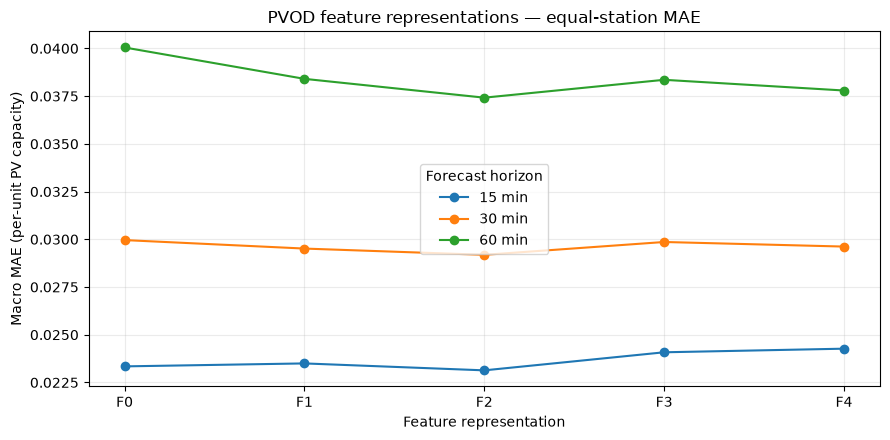

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for horizon in HORIZONS:
    row = mae_table.loc[horizon]
    ax.plot(("F0", "F1", "F2", "F3", "F4"),
            [row[name] for name in ("F0", "F1", "F2", "F3", "F4")],
            marker="o", label=f"{horizon} min")
ax.set_title("PVOD feature representations — equal-station MAE")
ax.set_xlabel("Feature representation")
ax.set_ylabel("Macro MAE (per-unit PV capacity)")
ax.grid(alpha=0.25)
ax.legend(title="Forecast horizon")
plt.tight_layout()
plt.show()

## 8. Save the cross-dataset results

The output tables contain station-level metrics, equal-station and pooled summaries, feature contrasts, paired intervals and the matched retrospective predictions. They provide the basis for the cross-dataset synthesis in Notebook 16.

In [8]:
OUTPUT = PROJECT_ROOT / "results" / "pvod_feature_comparison"
OUTPUT.mkdir(parents=True, exist_ok=True)
files = {
    "predictions": OUTPUT / "pvod_feature_predictions.csv.gz",
    "station_metrics": OUTPUT / "pvod_feature_station_metrics.csv",
    "aggregates": OUTPUT / "pvod_feature_aggregates.csv",
    "contrasts": OUTPUT / "pvod_feature_contrasts.csv",
    "selected_skill": OUTPUT / "pvod_selected_reference_skill.csv",
    "intervals": OUTPUT / "pvod_feature_intervals.csv",
    "populations": OUTPUT / "pvod_feature_populations.csv",
}
tables = {
    "predictions": predictions, "station_metrics": station_metrics,
    "aggregates": aggregates, "contrasts": contrasts,
    "selected_skill": selected_skill, "intervals": intervals,
    "populations": populations,
}
for name, path in files.items():
    tables[name].to_csv(path, index=False,
                        compression="gzip" if name == "predictions" else None,
                        float_format="%.12g")
    assert path.exists() and len(pd.read_csv(path)) == len(tables[name])
    print(path.relative_to(PROJECT_ROOT))
assert len(predictions) == 161_635
assert len(station_metrics) == 540
assert len(aggregates) == 54
assert len(contrasts) == 30
assert len(intervals) == 42
print("NOTEBOOK 10: PVOD CROSS-DATASET EVALUATION CHECKS PASSED")

results/pvod_feature_comparison/pvod_feature_predictions.csv.gz
results/pvod_feature_comparison/pvod_feature_station_metrics.csv
results/pvod_feature_comparison/pvod_feature_aggregates.csv
results/pvod_feature_comparison/pvod_feature_contrasts.csv
results/pvod_feature_comparison/pvod_selected_reference_skill.csv
results/pvod_feature_comparison/pvod_feature_intervals.csv
results/pvod_feature_comparison/pvod_feature_populations.csv
NOTEBOOK 10: PVOD CROSS-DATASET EVALUATION CHECKS PASSED


## Interpretation

The equal-station and station-specific results describe how the Gregorian, solar, continuous lunar and Panchang representations perform across PVOD sites. The F3–F4 differences and their paired intervals indicate the direction and stability of the categorical representation effect at each horizon. The continuous-sidereal comparison provides an additional control for the astronomical information underlying Panchang.

Cross-dataset conclusions will be developed by comparing these results with SOLETE in Notebook 16, while keeping the datasets' error units and prior test exposure explicit.